#### Search Algorithms

Search Algorithms
- A_Star (A*) Frontier Algorithm
- A_Star (A*) Algorithm (optalgotools)
- Beam Search Frontier Algorithm
- Beam Search Algorithm
- Kruskal Algorithm


#### A_Star Frontier Algorithm

In [ ]:
!pip install osmnx optalgotools > /dev/null

In [ ]:
import osmnx
from optalgotools.structures import Node
from optalgotools.routing import cost

import networkx as nx
import heapq

import matplotlib.pyplot as plt

**Graph Structure**

Build using networkx (G is converted to a directed graph) containing a custom set of node labels and edges with numerical travel costs as weight attributes.
Node Object Wrapping uses optalgotools- structures to wrap active nodes, manage their state, and dynamically trace backtracking paths.

**Frontier Search Logic (astar_frontier)**

Frontier tracks nodes scheduled for exploration (frontier list) and already visited nodes (explored set).
Cost Assessment minimizes the evaluation function $f(n) = g(n) + h(n)$, where $g(n)$ is the exact cost from the source to the node, calculated using the cost tracking dictionary to_source, $h(n)$ is the straight-line distance (heuristic) lookup from the current node to the goal.

**Path Construction**

When the destination node is reached, the optimal sequence of nodes is reconstructed backwards via the parent hierarchy.

**Heuristic Evaluation (heuristic_lookup)**

A static lookup dictionary, straight_line, stores the coordinate-independent straight-line heuristic distances to the target node 'G' (e.g., $h(G) = 0$, $h(P) = 7$, $h(A) = 11$).
The function heuristic_lookup parses node-object strings or attributes to retrieve these values dynamically.

**Pathfinding**

The algorithm executes to find the shortest path from source to destination resolving to the optimal route.
The network layout is rendered highlighting the path in red and other graph components in black.

In [ ]:
nodes = ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N',
         'O', 'P', 'Q', 'R']

edges =  [
    ('A', 'B', {'weight': 4}),
    ('A', 'C', {'weight': 3}),
    ('A', 'J', {'weight': 2}),
    ('B', 'D', {'weight': 5}),
    ('B', 'E', {'weight': 12}),
    ('C', 'D', {'weight': 7}),
    ('C', 'F', {'weight': 10}),
    ('C', 'P', {'weight': 5}),
    ('D', 'E', {'weight': 2}),
    ('D', 'H', {'weight': 3}),
    ('E', 'G', {'weight': 5}),
    ('F', 'G', {'weight': 16}),
    ('H', 'I', {'weight': 4}),
    ('H', 'K', {'weight': 2}),
    ('I', 'G', {'weight': 3}),
    ('J', 'H', {'weight': 5}),
    ('J', 'M', {'weight': 3}),
    ('K', 'L', {'weight': 3}),
    ('L', 'G', {'weight': 2}),
    ('M', 'N', {'weight': 4}),
    ('M', 'P', {'weight': 4}),
    ('N', 'O', {'weight': 2}),
    ('O', 'G', {'weight': 3}),
    ('P', 'Q', {'weight': 3}),
    ('Q', 'R', {'weight': 2}),
    ('R', 'G', {'weight': 3})
]

In [ ]:
'''
nodes_with_heuristics = [
    ("A", {"heuristic":11}),
    ("B", {"heuristic":6}),
    ("C", {"heuristic":11}),
    ("D", {"heuristic":6}),
    ("E", {"heuristic":4}),
    ("F", {"heuristic":12}),
    ("G", {"heuristic":0}),
    ("H", {"heuristic":8}),
    ("I", {"heuristic":3}),
    ("J", {"heuristic":14}),
    ("K", {"heuristic":5}),
    ("L", {"heuristic":2}),
    ("M", {"heuristic":7}),
    ("N", {"heuristic":5}),
    ("O", {"heuristic":3}),
    ("P", {"heuristic":7}),
    ("Q", {"heuristic":4}),
    ("R", {"heuristic":2}) ]
'''
# use straight line instaead since our graph is not complex for demonstration
straight_line = {
    "A": 11, "B": 6, "C": 11, "D": 6, "E": 4, "F": 12, "G": 0, "H": 8, "I": 3, "J": 14, "K": 5, "L": 2, "M": 7, "N": 5, "O": 3, "P": 7, "Q": 4, "R": 2
}

In [ ]:
G = nx.Graph()
G.add_nodes_from(nodes)
G.add_edges_from(edges)
G = G.to_directed()

In [ ]:
def astar_frontier(G, source, destination, heuristic_fn, cost_fn, cost_kwargs={}, expand_kwargs={}):
    """
    Computes the shortest path from source to destination using the A* algorithm.

    Parameters:
    - G: networkx.Graph, the graph containing the network topology
    - source: optalgotools.structures.Node, the starting node object wrapper
    - destination: optalgotools.structures.Node, the target node object wrapper
    - heuristic_fn: function, calculates h(n), the heuristic estimate to destination
    - cost_fn: function, calculates g(n), the actual travel path cost
    - cost_kwargs: dict, auxiliary arguments passed to the cost function
    - expand_kwargs: dict, auxiliary arguments passed to the node expansion routine
    """
    to_source = {}  # Tracks g(n) cost from the source to each node
    route = []
    frontier = list()

    # Initialize search with the source node
    frontier.append(source)
    to_source[source] = 0
    explored = set()
    found = False

    # Loop until the frontier is empty or target path is found
    while frontier and not found:
        # Select node in frontier with minimum f(n) = g(n) + h(n)
        node = min(frontier, key=lambda n: to_source[n] + heuristic_fn(G, n, destination))
        frontier.remove(node)
        explored.add(node)

        # Expand neighbor nodes
        for child in node.expand(**expand_kwargs):
            if child not in explored and child not in frontier:
                # Reached destination, extract path and stop
                if child == destination:
                    route = child.path()
                    found = True
                    continue
                frontier.append(child)
                # Record actual cost to reach child node
                to_source[child] = cost_fn(G, child.path(), **cost_kwargs)
    return route

def heuristic_lookup(G, node, destination):
    """
    Looks up straight-line heuristic values from node representation.
    """
    # Match node directly against keys in the straight-line heuristic dictionary
    for key, val in straight_line.items():
        if str(key) in repr(node) or (hasattr(node, 'node') and G[key] is node.node):
            return val

    # Fallback lookup through node properties
    for attr in dir(node):
        try:
            val = getattr(node, attr)
            if val in straight_line:
                return straight_line[val]
        except:
            continue
    raise KeyError(f"Could not resolve node identifier for {node}")

In [ ]:
# Run the A* pathfinding using the heuristic wrapper
result = astar_frontier(
    G,
    Node(G, 'P'),
    Node(G, 'G'),
    heuristic_lookup,
    cost,
    expand_kwargs={"attr_name": "weight"},
    cost_kwargs={"attr_name": "weight"},
)

print("Optimal path:", result)

Optimal path: ['P', 'Q', 'R', 'G']


In [ ]:
pos = {
    'P': (0.0, 1.0),
    'Q': (1.0, 1.0),
    'R': (2.0, 1.0),
    'G': (3.0, 1.0),
    'A': (0.5, 2.5),
    'B': (0.5, -0.5),
    'C': (1.5, 2.5),
    'D': (1.5, -0.5),
    'E': (2.5, 2.5),
    'F': (2.5, -0.5),
    'H': (1.0, 0.0),
    'I': (2.0, 0.0),
    'J': (0.0, 2.0),
    'K': (1.0, -1.0),
    'L': (2.0, -1.0),
    'M': (0.0, 0.0),
    'N': (0.5, 0.5),
    'O': (2.5, 0.5)
}

In [ ]:
node_colors = ['r' if n == 'P' or n == 'G' else 'k' for n in list(G.nodes)]

# Create a set of highlighted edge tuples directly matching our path
highlighted_edges = set(zip(result[:-1], result[1:]))

# Color the edges red if they are on our path, black otherwise
edge_colors = ['r' if e in highlighted_edges else 'k' for e in G.edges]
edge_widths = [4 if e in highlighted_edges else 1 for e in G.edges]
labels = nx.get_edge_attributes(G, 'weight')

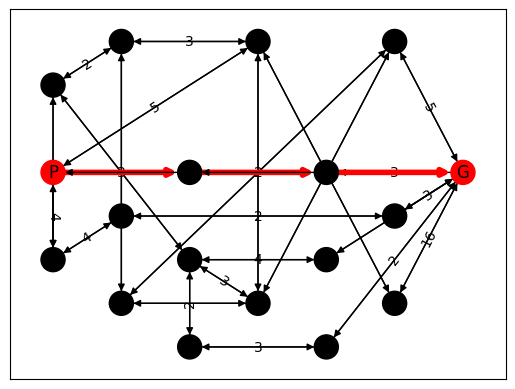

In [ ]:
# 1. Compute a default spring layout for all nodes in G
full_pos = nx.spring_layout(G, seed=42)

# 2. Override with our manually defined positions
for node, coords in pos.items():
    if node in full_pos:
        full_pos[node] = coords

# 3. Draw the graph using the complete position mapping
nx.draw_networkx_edge_labels(G, full_pos, edge_labels=labels)
nx.draw_networkx(G, full_pos, node_color=node_colors, edge_color=edge_colors, width=edge_widths, with_labels=True)
plt.show()

#### AStar* Algorithm (optalgotools)

A* Search Algorithm using optalgotools library  finds the shortest route on a geospatial network using a heuristic guided approach. It uses a pathfinder (A_Star) from graph search. It incorporates the Haversine distance heuristic to calculate the great-circle distance between the current node and the destination. It utilizes node and solution wrapper classes to keep track of spatial coordinated, path costs, and metrics like elapsed processing time, memory footprint and explored nodes.

In [ ]:
!pip install osmnx optalgotools >/dev/null

In [ ]:
# Import necessary libraries for geospatial data, algorithms, search, and plotting
import osmnx
from optalgotools.routing import (
    astar_heuristic, cost, draw_route, get_child, randomized_search)
from optalgotools.structures import Node, Solution
from optalgotools.algorithms.graph_search import A_Star
from optalgotools.utilities import haversine_distance

from itertools import islice
from sys import getsizeof
from time import process_time

import heapq

import numpy as np
import matplotlib.pyplot as plt

In [ ]:
center = (40.766876, -73.979076)
source_point = (40.767686, -73.978591)
destination_point = (40.758815, -73.998772)
reference = (40.766876, -73.979076)

# Create the spatial graph from the center point
G = osmnx.graph_from_point(reference, dist=300, simplify=True)

# Get the ID of the nearest node to the source and destination coordinate pairs
source_id = osmnx.distance.nearest_nodes(G, source_point[1], source_point[0])
destination_id = osmnx.distance.nearest_nodes(G, destination_point[1], destination_point[0])

# Wrap IDs into Node objects for compatibility with the optalgotools library
source = Node(graph=G, osmid=source_id)
destination = Node(graph=G, osmid=destination_id)

# Run the A* algorithm using the custom haversine distance heuristic
soln = A_Star(G, source, destination, astar_heuristic, heuristic_kwargs={'measuring_dist': haversine_distance})
route = soln.result

# Output metrics including total route cost, runtime, space usage, and explored nodes count
print(f'Cost: {cost(G,route)} m')
print(f'Processing time: {soln.time} seconds')
print(f'Space required: {soln.space} bytes')
print(f'Explored nodes: {soln.explored}')

Cost: 745.8841 m
Processing time: 0.0023991779999992247 seconds
Space required: 2264 bytes
Explored nodes: 50


#### Beam Search Frontier Algorithm

In [ ]:
!pip install osmnx optalgotools > /dev/null

In [ ]:
import osmnx
from optalgotools.structures import Node
from optalgotools.routing import cost

import networkx as nx
import heapq

import matplotlib.pyplot as plt

#### Algorithm Implementation
**Algorithm Integration**: The custom beam-search-frontier function correctly coordinates with node structure of networkx. It leverages node expand to dynamically branch state and correctly tracks visited nodes.

**Heuristic & Cost Evaluation**: The search safely evaluates candidate nodes on the frontier using your selected cost metric (cost_-n) from the graph edges. The graph is properly converted to a directed structure prior to traversal, ensuring that bidirectional edge transitions are explicitly handled by the search engine.

**Efficiency & Complexity**: Beam width w, keeping a restricted width (currently $w=2$) prevents the search frontier from expanding exponentially. This is optimal for resource-constrained or large-scale graphs.

**Data Structures**: Utilizing heapq.nsmallest directly on the search pool provides an $O(k \log w)$or $O(k + w \log k)$ extraction of the best nodes, which is highly efficient. For even larger graphs, keeping the pool itself as a min-heap rather than sorting a set at each step can further optimize performance.

**Heuristic Search**: The search uses the path cost. To convert this into a true directed heuristic search (like A* with Beam Search), customize cost_fn inside the key parameter to combine the current cumulative path cost with your defined straight_line heuristic dictionary (f(n) = g(n) + h(n)).

In [ ]:
nodes = ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N',
         'O', 'P', 'Q', 'R']

edges =  [
    ('A', 'B', {'weight': 4}),
    ('A', 'C', {'weight': 3}),
    ('A', 'J', {'weight': 2}),
    ('B', 'D', {'weight': 5}),
    ('B', 'E', {'weight': 12}),
    ('C', 'D', {'weight': 7}),
    ('C', 'F', {'weight': 10}),
    ('C', 'P', {'weight': 5}),
    ('D', 'E', {'weight': 2}),
    ('D', 'H', {'weight': 3}),
    ('E', 'G', {'weight': 5}),
    ('F', 'G', {'weight': 16}),
    ('H', 'I', {'weight': 4}),
    ('H', 'K', {'weight': 2}),
    ('I', 'G', {'weight': 3}),
    ('J', 'H', {'weight': 5}),
    ('J', 'M', {'weight': 3}),
    ('K', 'L', {'weight': 3}),
    ('L', 'G', {'weight': 2}),
    ('M', 'N', {'weight': 4}),
    ('M', 'P', {'weight': 4}),
    ('N', 'O', {'weight': 2}),
    ('O', 'G', {'weight': 3}),
    ('P', 'Q', {'weight': 3}),
    ('Q', 'R', {'weight': 2}),
    ('R', 'G', {'weight': 3})
]

In [ ]:
'''
nodes_with_heuristics = [
    ("A", {"heuristic":11}),
    ("B", {"heuristic":6}),
    ("C", {"heuristic":11}),
    ("D", {"heuristic":6}),
    ("E", {"heuristic":4}),
    ("F", {"heuristic":12}),
    ("G", {"heuristic":0}),
    ("H", {"heuristic":8}),
    ("I", {"heuristic":3}),
    ("J", {"heuristic":14}),
    ("K", {"heuristic":5}),
    ("L", {"heuristic":2}),
    ("M", {"heuristic":7}),
    ("N", {"heuristic":5}),
    ("O", {"heuristic":3}),
    ("P", {"heuristic":7}),
    ("Q", {"heuristic":4}),
    ("R", {"heuristic":2}) ]
'''
# use straight line instaead since our graph is not complex for demonstration
straight_line = {
    "A": 11, "B": 6, "C": 11, "D": 6, "E": 4, "F": 12, "G": 0, "H": 8, "I": 3, "J": 14, "K": 5, "L": 2, "M": 7, "N": 5, "O": 3, "P": 7, "Q": 4, "R": 2
}

In [ ]:
G = nx.Graph()
G.add_nodes_from(nodes)
G.add_edges_from(edges)
G = G.to_directed()

In [ ]:
def beam_search_frontier(G, source, destination, cost_fn, w=2, expand_kwargs = {}, cost_kwargs = {}):
  """
  Performs a beam search over a graph's frontier to find a path from source to destination.

  Parameters:
  ----------
  G : networkx.Graph
      The graph over which to perform the search.
  source : optalgotools.structures.Node
      The starting node instance for the search.
  destination : optalgotools.structures.Node
      The destination node instance to reach.
  cost_fn : function
      A function used to evaluate path costs. Expected signature: cost_fn(G, path, **kwargs).
  w : int, optional
      The beam width representing the maximum number of paths to keep in the frontier (default is 2).
  expand_kwargs : dict, optional
      Keyword arguments to pass to the Node.expand() method during node expansion.
  cost_kwargs : dict, optional
      Keyword arguments to pass to the cost_fn during path evaluation.

  Returns:
  -------
  list or None
      A list of node IDs representing the path from source to destination if found, else None.
  """
  seen = set()
  seen.add(source)
  last_beam = None

  # Initialize the pool of candidate nodes from the starting node's neighbors
  pool = set(source.expand(**expand_kwargs))
  beam = []

  while beam != last_beam:
    last_beam = list(beam)
    # Select the 'w' best candidate nodes from the pool based on their accumulated path cost
    beam = heapq.nsmallest(
        w, pool, key=lambda x: cost_fn(G, x.path(), **cost_kwargs))

    if not beam:
      break

    # Explore the highest priority candidate in the current beam
    current = beam.pop(0)
    seen.add(current)
    pool.remove(current)

    # Expand neighbors of the current candidate
    children = set(current.expand(**expand_kwargs))
    for child in children:
      if child in seen:
        continue
      else:
        # Check if destination is reached
        if child == destination:
          return child.path()
        beam.append(child)

    # Update pool with remaining beam candidates for the next iteration
    pool.update(beam)

  return None

In [ ]:
result = beam_search_frontier(
    G,
    Node(G, 'P'),
    Node(G, 'G'),
    cost,
    expand_kwargs={'attr_name': 'weight'},
    cost_kwargs={'attr_name': 'weight'}
)

pos = {
    'P': (0.0, 1.0),
    'Q': (1.0, 1.0),
    'R': (2.0, 1.0),
    'G': (3.0, 1.0),
    'A': (0.5, 2.5),
    'B': (0.5, -0.5),
    'C': (1.5, 2.5),
    'D': (1.5, -0.5),
    'E': (2.5, 2.5),
    'F': (2.5, -0.5),
    'H': (1.0, 0.0),
    'I': (2.0, 0.0),
    'J': (0.0, 2.0),
    'K': (1.0, -1.0),
    'L': (2.0, -1.0),
    'M': (0.0, 0.0),
    'N': (0.5, 0.5),
    'O': (2.5, 0.5)
}

In [ ]:
node_colors = ['r' if n == 'P' or n == 'G' else 'k' for n in list(G.nodes)]

# Create a set of highlighted edge tuples directly matching our path
highlighted_edges = set(zip(result[:-1], result[1:]))

# Color the edges red if they are on our path, black otherwise
edge_colors = ['r' if e in highlighted_edges else 'k' for e in G.edges]
edge_widths = [4 if e in highlighted_edges else 1 for e in G.edges]
labels = nx.get_edge_attributes(G, 'weight')

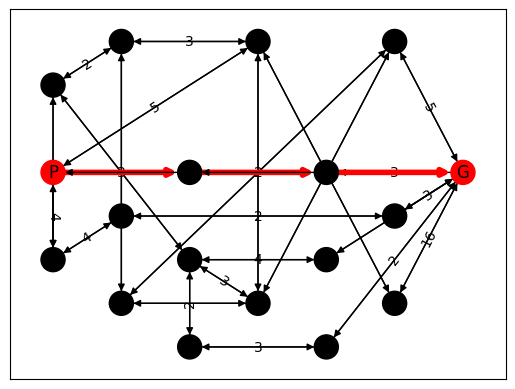

In [ ]:
# 1. Compute a default spring layout for all nodes in G
full_pos = nx.spring_layout(G, seed=42)

# 2. Override with our manually defined positions
for node, coords in pos.items():
    if node in full_pos:
        full_pos[node] = coords

# 3. Draw the graph using the complete position mapping
nx.draw_networkx_edge_labels(G, full_pos, edge_labels=labels)
nx.draw_networkx(G, full_pos, node_color=node_colors, edge_color=edge_colors, width=edge_widths, with_labels=True)
plt.show()

#### Beam Search (V2)

Beam Search Algorithm performs a heuristic pathfinding search that limits memory exploration by maintaining only the top optimal pathways at any given step with the beam width. One method generated up to n child nodes for each part in the current beam, allowing algorithm to branch out forward. The search algorithm initializes k-randomized paths from the source to the target. It expands paths and keeps track of visited routes inside a visited set. Employs heapq smallest to prune the active candidate pool, keeping only k most efficient routed at each iteration step.




Set point of interest

In [ ]:
center = (40.766876, -73.979076)
source_point = (40.767686, -73.978591)
destination_point = (40.758815, -73.998772)
reference = (40.766876, -73.979076)

# create the graph
G = osmnx.graph_from_point(reference, dist=300, simplify=True)

# get the id of the nearest node to the source and destination points
source_id = osmnx.distance.nearest_nodes(G, source_point[1], source_point[0])
destination_id = osmnx.distance.nearest_nodes(G, destination_point[1], destination_point[0])

# convert source and destination nodes to node
source = Node(graph=G, osmid=source_id)
destination = Node(graph=G, osmid=destination_id)

Beam Search Algorithm

In [ ]:
def get_beam(G, beam, n=20):
    new_beam = []
    for route in beam:
        neighbors = list(islice(get_child(G, route), n))
        new_beam.extend(neighbors)
    return new_beam

In [ ]:
def beam_search_v2(G, source, destimation, k=10, n=20):
    """
    Executes a Beam Search algorithm on a spatial graph G to find an optimal path.

    Parameters:
    G (networkx.MultiDiGraph): The spatial graph environment.
    source (Node): The starting node object containing the osmid.
    destination (Node): The target node object containing the osmid.
    k (int, optional): The beam width (number of top paths to maintain). Defaults to 10.
    n (int, optional): The max number of child nodes/routes to generate per path. Defaults to 20.

    Returns:
    Solution: A solution object containing the optimal path, execution time, peak space required, and historical path cost matrix.
    """
    # 1. Start execution timing for benchmarking
    start_time = process_time()
    seen = set()
    costs = []

    # 2. Initialize the search space with k randomized paths from source to destination
    beam = [randomized_search(G, source.osmid, destination.osmid)
            for _ in range(k)]

    # 3. Track evaluated paths in a set to avoid processing duplicate routes
    for route in beam:
        seen.add(tuple(route))

    pool = []
    # 4. Expand initial beam paths by finding their neighboring routes
    children = get_beam(G, beam, n)
    costs.append([cost(G, r) for r in beam])

    # 5. Filter out duplicate pathways and populate our active candidates pool
    for child in children:
        if tuple(child) in seen:
            continue
        else:
            pool.append(child)
            seen.add(tuple(child))
    pool += beam
    space_required = getsizeof(pool)
    last_beam = None

    # 6. Begin iterative local search optimization loop
    while beam != last_beam:
        last_beam = beam
        # Keep only the top k paths with the lowest physical cost
        beam = heapq.nsmallest(k, pool, key=lambda x: cost(G, x))

        for route in beam:
            seen.add(tuple(route))

        pool = []
        # Generate new neighboring candidates from the current k-best paths
        children = get_beam(G, beam, n)
        costs.append([cost(G, r) for r in beam])
        for child in children:
            if tuple(child) in seen:
                continue
            else:
                pool.append(child)
                seen.add(tuple(child))
        pool += beam
        # Measure maximum memory space consumed by the search pool
        space_required = (getsizeof(pool) if getsizeof(pool) > space_required else space_required)

    # 7. Select the ultimate best route from our stable optimized beam
    route = min(beam, key=lambda x: cost(G, x))
    end_time = process_time()

    return Solution(
        route, end_time - start_time, space_required, np.rot90(costs))

Find the shortest route

Cost: 569.2878 m
Processing time: 65.79103791899979 seconds
Space required: 1656 bytes


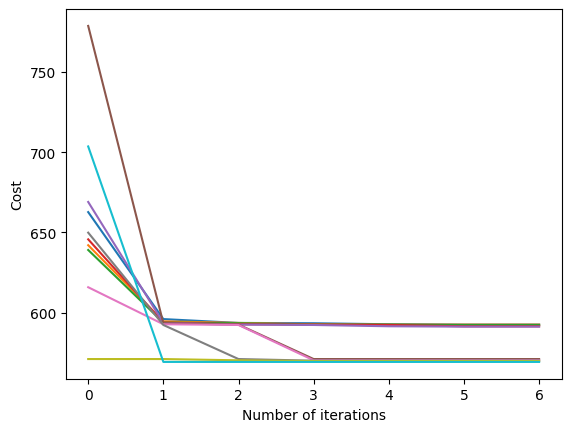

In [ ]:
solution = beam_search_v2(G, source, destination, k=10, n=20)
route = solution.result
print(f'Cost: {cost(G,route)} m')
print(f'Processing time: {solution.time} seconds')
print(f'Space required: {solution.space} bytes')
for c in solution.explored:
    plt.plot(c)
plt.xticks(list(range(len(solution.explored[0]))))
plt.xlabel('Number of iterations')
plt.ylabel('Cost')
plt.show()

#### Kruskal Algorithm

Kruskal Algorithm  computes the Minimum Spanning Tree (MST) of a connected undirected graph, linking all nodes with minimum possible total edge weight and without any cycles. Sorts all the edges based on their IDs, performs iterative tree assembly, prevents cycles and checks if spanning tree is fully connected for early termination.

Create a graph

In [ ]:
from __future__ import annotations
from typing import *
from typing_extensions import Protocol
T = TypeVar('T')

class Comparable(Protocol):
    def __eq__(self, other: Any) -> bool: ...
    def __lt__(self: T, other: T) -> bool: ...
    def __gt__(self: T, other: T) -> bool:
        return (not self < other) and  self == other
    def __le__(self: T, other: T) -> bool:
        return self < other or self == other
    def __ge__(self: T, other: T) -> bool:
        return not self < other

In [ ]:
def Kruskal(G, attr='length'):
    """
    Computes the Minimum Spanning Tree (MST) of a given graph using Kruskal's Algorithm.

    Parameters:
    G (networkx.Graph / networkx.MultiGraph): The input graph on which to construct the MST.
    attr (str, optional): The edge attribute representing weight or distance. Defaults to 'length'.

    Returns:
    networkx.Graph: An undirected simple Graph representing the Minimum Spanning Tree.
    """
    # 1. Sort all edges based on their ID attribute (falling back to 1 if missing) to ensure a deterministic order
    edges = sorted(G.edges(data=True), key=lambda t: str(t[2].get('osmid', 1)))

    # 2. Initialize an empty undirected Graph with the same nodes as the input graph
    mst = nx.Graph()
    mst.add_nodes_from(G)

    # 3. Iterate through sorted edges and try to add each to the spanning tree
    for edge in edges:
        # Ensure length attribute is converted to an integer
        edge[2]['length'] = int(edge[2]['length'])
        mst.add_edges_from([edge])

        try:
            # 4. Use cycle detection to see if adding this edge closes a cycle
            nx.find_cycle(mst)
            mst.remove_edge(edge[0], edge[1])
        except nx.NetworkXNoCycle:
            # 5. If no cycle is formed, keep the edge. Check if the spanning tree is now fully connected
            if nx.is_connected(mst):
                break
            continue
    return mst

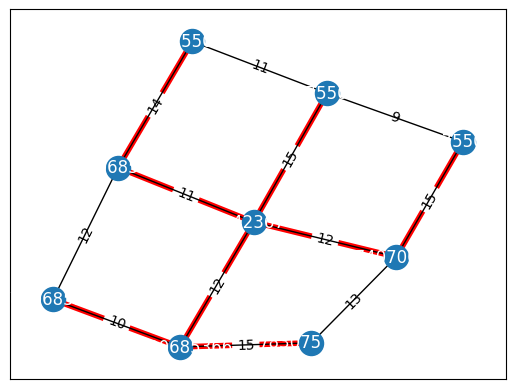

In [ ]:
G = nx.Graph()
G.add_nodes_from([42423674, 7830685366, 7830685378, 1740700804, 4347550033, 7830685373, 4347550047, 4347550043, 7830757210])

edges = [
    (42423674, 7830685366, {'length': 12}), (42423674, 7830685378, {'length': 11}), (7830685378, 42423674, {'length': 11}), (42423674, 1740700804, {'length': 12}), (1740700804, 42423674, {'length': 12}), (42423674, 4347550047, {'length': 15}), (4347550047, 42423674, {'length': 15}),  (7830685373, 7830685366, {'length': 10}), (7830685378, 4347550033, {'length': 14}), (7830685373, 7830685378, {'length': 12}), (7830685378, 7830685373, {'length': 12}),  (7830685366, 7830757210, {'length': 15}), (7830757210, 7830685366, {'length': 15}),  (7830685366, 7830685373, {'length': 10}), (4347550043, 4347550047, {'length': 9}), (4347550047, 4347550043, {'length': 9}), (4347550033, 4347550047, {'length': 11}), (4347550047, 4347550033, {'length': 11}), (1740700804, 4347550043, {'length': 15}), (4347550043, 1740700804, {'length': 15}), (1740700804, 7830757210, {'length': 13}), (7830757210, 1740700804, {'length': 13})
]

G.add_edges_from(edges)
pos = nx.spring_layout(G, seed=30)
MST = Kruskal(G).edges
labels = nx.get_edge_attributes(G, 'length')
nx.draw_networkx_edges(G, pos, list(MST), width=4, edge_color='red')
nx.draw_networkx_edge_labels(G, pos, edge_labels=labels)
nx.draw_networkx(G, pos, with_labels=True, font_color='white')
plt.show()

Create a second graph

In [ ]:
# Set point of interest
center = (40.766876, -73.979076)
source_point = (40.767686, -73.978591)
destination_point = (40.758815, -73.998772)
reference = (40.766876, -73.979076)
# create the graph
G = osmnx.graph_from_point(reference, dist=25, simplify=True)
G.edges

OutMultiEdgeView([(42423674, 4347550047, 0), (42423674, 7830685378, 0), (42423674, 1740700804, 0), (42423674, 7830685366, 0), (1740700804, 42423674, 0), (1740700804, 4347550043, 0), (1740700804, 7830757210, 0), (4347550033, 7830685378, 0), (4347550033, 4347550047, 0), (4347550043, 4347550047, 0), (4347550043, 1740700804, 0), (4347550047, 42423674, 0), (4347550047, 4347550033, 0), (4347550047, 4347550043, 0), (7830685366, 7830757210, 0), (7830685366, 7830685373, 0), (7830685373, 7830685378, 0), (7830685373, 7830685366, 0), (7830685378, 42423674, 0), (7830685378, 7830685373, 0), (7830685378, 4347550033, 0), (7830757210, 7830685366, 0), (7830757210, 1740700804, 0)])

In [ ]:
pos = nx.spring_layout(G, seed=30)

EdgeView([(42423674, 7830685366), (42423674, 7830685378), (42423674, 1740700804), (42423674, 4347550047), (4347550033, 7830685378), (4347550043, 4347550047), (7830685366, 7830685373), (7830685366, 7830757210)])

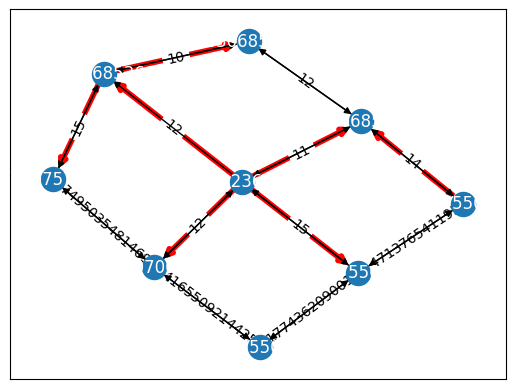

In [ ]:
MST = Kruskal(G).edges
labels = nx.get_edge_attributes(G, 'length')
nx.draw_networkx_edges(G, pos, list(MST), width=4, edge_color='red')
nx.draw_networkx_edge_labels(G, pos, edge_labels=labels)
nx.draw_networkx(G, pos, with_labels=True, font_color='white')
MST